# Statistical Process Control: CNC Brake Caliper Bore

**Author:** Areej Alsobh, Quality Engineer (automotive)

**Tools:** Python (pandas, NumPy, Matplotlib, SciPy). The SQL part of the project is in a separate folder.

## The business question

The Quality Manager is preparing for a customer PPAP review. The customer requires **Cpk ≥ 1.33** on the bore diameter.

> **Is the process capable? If not, why not, and what should be fixed first?**

| Characteristic | Specification |
|---|---|
| Bore diameter | Ø 42.000 ± 0.025 mm (LSL 41.975, USL 42.025) |
| Surface roughness | Ra ≤ 1.6 µm (upper limit only) |
| Sampling | Subgroups of 5 consecutive parts every 2 hours |
| Machines | CNC-01, CNC-02, CNC-03, three shifts (A 06–14, B 14–22, C 22–06) |
| Period | 5 January – 26 June 2026 |

> **Note on the data:** the dataset is **synthetic**. It was generated to practise SPC on realistic machining behaviour (tool wear, setup errors, material lots, shift effects). The methods are the same ones used on real plant data.

## Executive summary

- **No machine meets the requirement over the full period.** Ppk is 1.10 (CNC-01), 0.93 (CNC-02) and 0.96 (CNC-03), against 1.33 required.
- **The machines themselves are capable** (Cp 1.44–1.63) and well centred. Capability is lost **over time**, mainly through **tool-wear drift**: the bore shrinks by about 0.014 mm over each tool's life, 28% of the tolerance.
- **Four specific events add to it:**
  - an offset error on CNC-02 at tool changes (16–25 March);
  - a tool breakage on CNC-01 (12 May);
  - a wider spread on CNC-03's night shift after an operator change (from April);
  - one over-hard material lot that caused 137 of the 140 roughness failures (25–29 May).
- **A fix already exists:** from 1 June, CNC-01 runs with tool-wear compensation, and its **Ppk rose from 1.05 to 1.55** (statistically confirmed, with the other machines as a control group).
- **Recommended first action:** roll out wear compensation to CNC-02 and CNC-03. It removes the biggest single cause on every machine, without the extra tool cost and tool-change risk of shorter tool-change intervals.

## Contents

1. Data cleaning
2. X̄-R control charts and Western Electric rules
3. Explaining the patterns with the tool change log
4. Process capability (Cp, Cpk, Pp, Ppk)
5. Capability histograms
6. Stratifying the variation by shift and operator
7. Surface roughness: one-sided capability and material lots
8. Verifying an improvement (CNC-01, June)
9. Tool life: how fast does the bore drift?
10. Conclusions and recommendations

## Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Specification
USL, LSL, NOMINAL = 42.025, 41.975, 42.000
USL_RA = 1.6                                  # roughness, upper limit only

# Control chart constants for subgroups of n = 5
A2, D3, D4, d2 = 0.577, 0, 2.114, 2.326

# Chart style
BLUE, RED, GREY, ORANGE, PURPLE = '#2a78d6', '#d03b3b', '#8a8a8a', '#e08a00', '#7b3fb5'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'figure.dpi': 100})

# Data
df_raw       = pd.read_csv('../data/measurements.csv')
df_tools     = pd.read_csv('../data/tool_changes.csv', parse_dates=['change_timestamp'])
df_lots      = pd.read_csv('../data/material_lots.csv')
df_operators = pd.read_csv('../data/operators.csv')

print(f'measurements: {df_raw.shape[0]:,} rows, {df_raw.shape[1]} columns')

measurements: 22,538 rows, 11 columns


## 1. Data cleaning

Three problems were found during profiling (and confirmed with SQL):

1. **Two timestamp formats.** CNC-03 writes dates day-first (`dd/mm/yyyy`), the others ISO (`yyyy-mm-dd`).
2. **Exact duplicate rows**, the same measurement stored twice under different IDs.
3. **Missing and impossible diameters** (outside 41.9–42.1 mm, physically impossible for this part).

In [2]:
df_measurements = df_raw.copy()

# 1. Parse both timestamp formats, then combine
ts_iso = pd.to_datetime(df_measurements['timestamp'], format='%Y-%m-%d %H:%M', errors='coerce')
ts_dmy = pd.to_datetime(df_measurements['timestamp'], format='%d/%m/%Y %H:%M', errors='coerce')
df_measurements['measured_at'] = ts_iso.fillna(ts_dmy)

# 2. Remove exact duplicates (every column equal except the ID), keep the first
cols_to_compare = df_measurements.columns.drop('measurement_id')
n_before = len(df_measurements)
df_measurements = (df_measurements.sort_values('measurement_id')
                                  .drop_duplicates(subset=cols_to_compare, keep='first'))

# 3. Flag diameters; keep the rows (roughness is still valid) but blank the bad diameters
d = df_measurements['bore_diameter_mm']
df_measurements['diameter_flag'] = np.select([d.isna(), ~d.between(41.9, 42.1)],
                                             ['Missing', 'Impossible'], default='OK')
df_measurements['bore_diameter_clean'] = d.where(df_measurements['diameter_flag'] == 'OK')

print(f'Unparsed timestamps : {df_measurements["measured_at"].isna().sum()}')
print(f'Duplicates removed  : {n_before - len(df_measurements)}')
print(f'Rows after cleaning : {len(df_measurements):,}')
df_measurements['diameter_flag'].value_counts()

Unparsed timestamps : 0
Duplicates removed  : 38
Rows after cleaning : 22,500


,count
diameter_flag,
OK,22396
Missing,90
Impossible,14


**Cleaning decisions**

| Issue | Count | Decision | Reason |
|---|---|---|---|
| Duplicate rows | 38 | Removed | The same measurement stored twice would be counted twice |
| Missing diameter | 90 | Row kept, diameter blank | The roughness value on these rows is still valid (used in section 7) |
| Impossible diameter | 14 | Row kept, diameter blank, flagged | Measurement or entry errors, not real parts; the flag keeps them traceable |
| Mixed timestamps | all CNC-03 rows | Both formats parsed | All 22,500 timestamps parsed, none lost |

## 2. X̄-R control charts and Western Electric rules

Each subgroup of 5 parts gives two points: the **mean (X̄)**, which shows where the process is centred, and the **range (R)**, which shows how consistent the 5 parts are. Control limits come from **January** (the baseline period), and the rest of the period is judged against them.

Only complete subgroups (n = 5) are used. 104 subgroups with a missing or impossible value are left out.

In [3]:
subgroups = (df_measurements.groupby(['machine_id', 'subgroup_id'])
             .agg(measured_at=('measured_at', 'min'),
                  shift=('shift', 'first'),
                  operator_id=('operator_id', 'first'),
                  tool_id=('tool_id', 'first'),
                  xbar=('bore_diameter_clean', 'mean'),
                  R=('bore_diameter_clean', lambda s: s.max() - s.min()),
                  n=('bore_diameter_clean', 'count'))
             .reset_index())
subgroups = subgroups[subgroups['n'] == 5].copy()

# Control limits from the January baseline
january = subgroups[subgroups['measured_at'] < '2026-02-01']
limits = (january.groupby('machine_id')
          .agg(X_double_bar=('xbar', 'mean'), R_bar=('R', 'mean'))
          .reset_index())
limits['UCL_X'] = limits['X_double_bar'] + A2 * limits['R_bar']
limits['LCL_X'] = limits['X_double_bar'] - A2 * limits['R_bar']
limits['UCL_R'] = D4 * limits['R_bar']
limits['LCL_R'] = D3 * limits['R_bar']

print(f'Complete subgroups: {len(subgroups):,}')
limits.round(4)

Complete subgroups: 4,396


,machine_id,X_double_bar,R_bar,UCL_X,LCL_X,UCL_R,LCL_R
0,CNC-01,41.9994,0.0115,42.0060,41.9928,0.0243,0.0
1,CNC-02,41.9978,0.0126,42.0051,41.9906,0.0266,0.0
2,CNC-03,41.9988,0.0121,42.0057,41.9918,0.0256,0.0


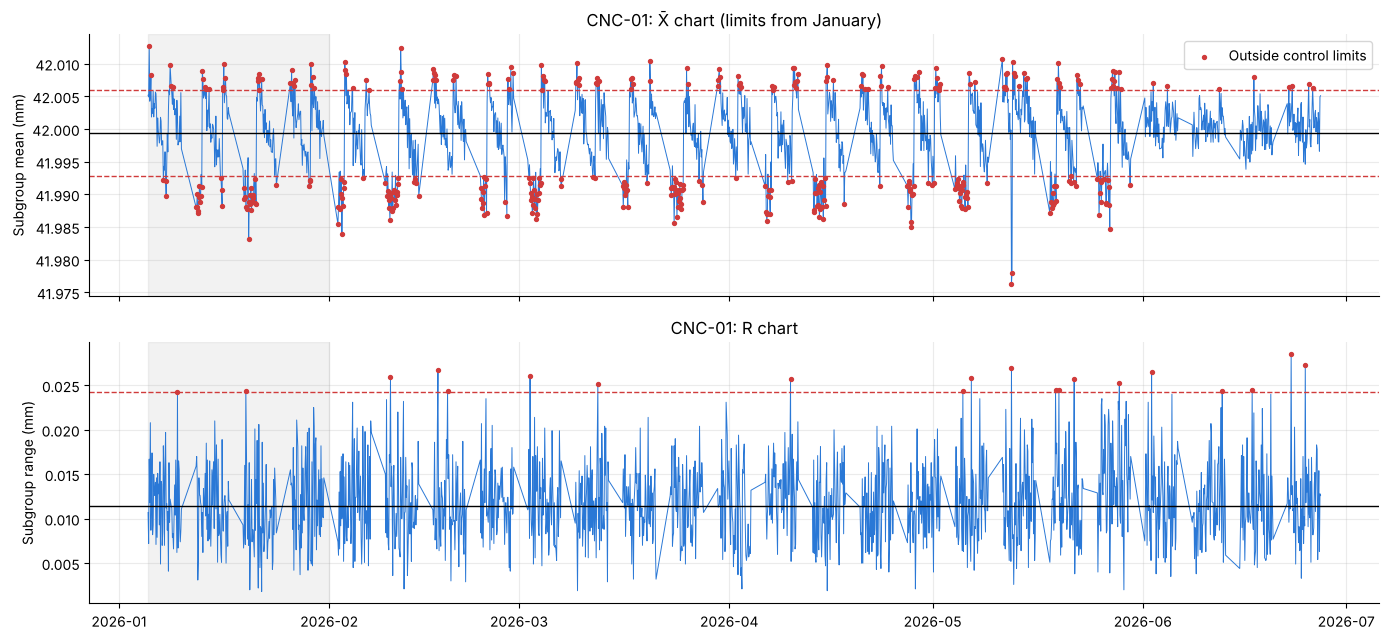

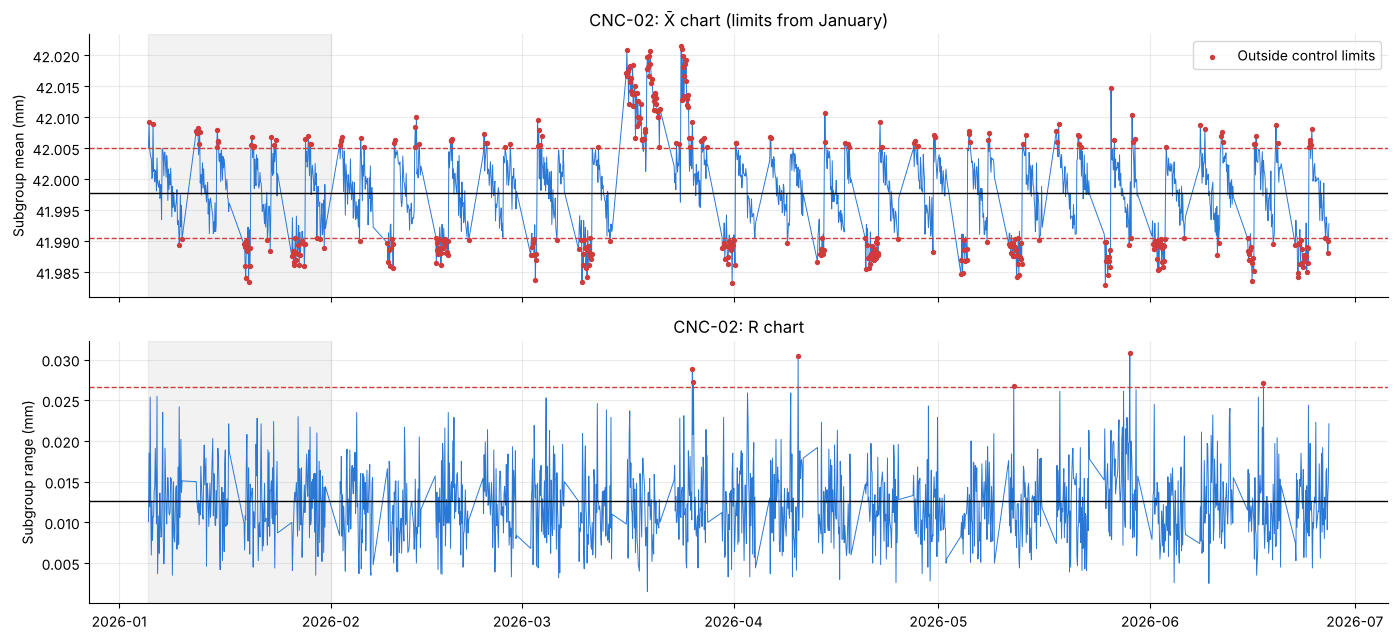

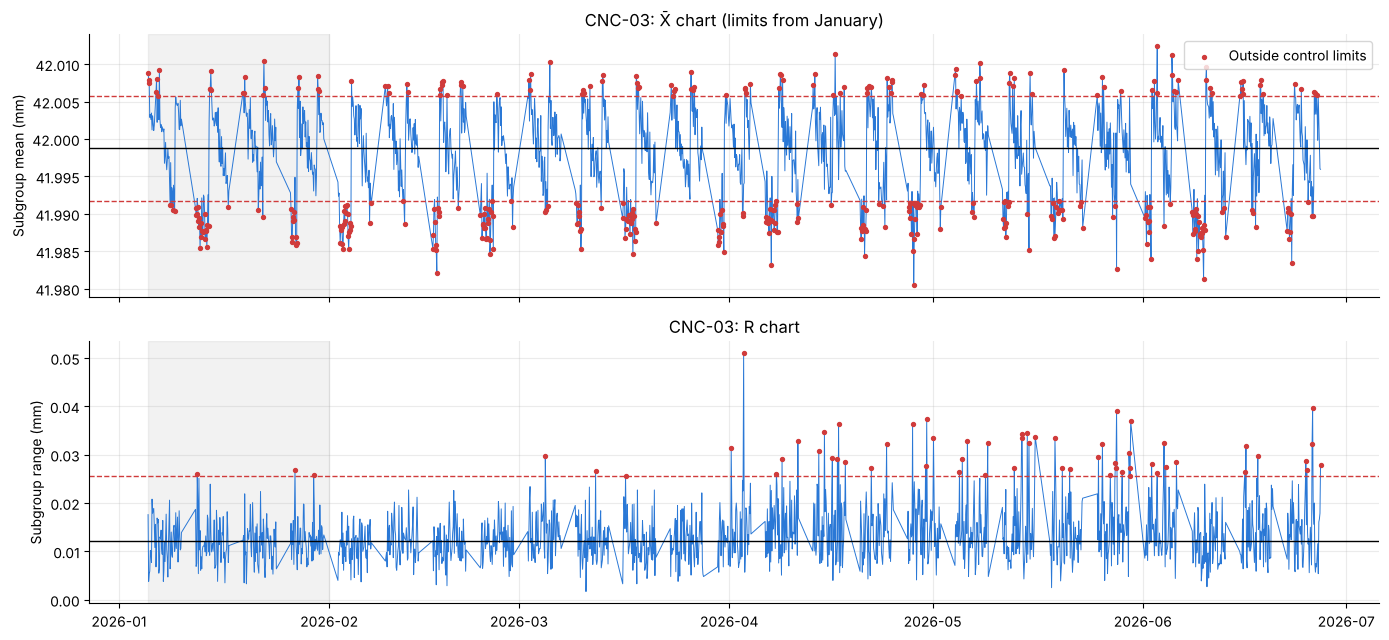

In [4]:
chart = subgroups.merge(limits, on='machine_id').sort_values(['machine_id', 'measured_at']).reset_index(drop=True)
chart['x_out'] = (chart['xbar'] > chart['UCL_X']) | (chart['xbar'] < chart['LCL_X'])
chart['r_out'] = (chart['R'] > chart['UCL_R']) | (chart['R'] < chart['LCL_R'])

def plot_xbar_r(machine):
    data = chart[chart['machine_id'] == machine]
    lim = limits[limits['machine_id'] == machine].iloc[0]
    fig, (ax_x, ax_r) = plt.subplots(2, 1, figsize=(14, 6.5), sharex=True)

    ax_x.plot(data['measured_at'], data['xbar'], color=BLUE, lw=0.7)
    ax_x.scatter(data.loc[data['x_out'], 'measured_at'], data.loc[data['x_out'], 'xbar'],
                 color=RED, s=8, zorder=3, label='Outside control limits')
    ax_x.axhline(lim['X_double_bar'], color='black', lw=1)
    for v in (lim['UCL_X'], lim['LCL_X']):
        ax_x.axhline(v, color=RED, ls='--', lw=1)
    ax_x.set_ylabel('Subgroup mean (mm)')
    ax_x.set_title(f'{machine}: X̄ chart (limits from January)')
    ax_x.legend(loc='upper right')

    ax_r.plot(data['measured_at'], data['R'], color=BLUE, lw=0.7)
    ax_r.scatter(data.loc[data['r_out'], 'measured_at'], data.loc[data['r_out'], 'R'],
                 color=RED, s=8, zorder=3)
    ax_r.axhline(lim['R_bar'], color='black', lw=1)
    ax_r.axhline(lim['UCL_R'], color=RED, ls='--', lw=1)
    ax_r.set_ylabel('Subgroup range (mm)')
    ax_r.set_title(f'{machine}: R chart')

    for ax in (ax_x, ax_r):
        ax.axvspan(data['measured_at'].min(), pd.Timestamp('2026-02-01'), color='grey', alpha=0.1)
    plt.tight_layout()
    plt.show()

for machine in limits['machine_id']:
    plot_xbar_r(machine)

**Western Electric rules** also catch patterns *inside* the limits. The distance of each point from the centre line is measured in sigmas (z):

| Rule | Signal |
|---|---|
| 1 | 1 point beyond 3σ |
| 2 | 2 of 3 consecutive points beyond 2σ, same side |
| 3 | 4 of 5 consecutive points beyond 1σ, same side |
| 4 | 8 consecutive points on the same side of the centre line |

In [5]:
chart['sigma'] = (chart['UCL_X'] - chart['X_double_bar']) / 3
chart['z'] = (chart['xbar'] - chart['X_double_bar']) / chart['sigma']
z_by_machine = chart.groupby('machine_id')['z']

chart['rule1'] = chart['z'].abs() > 3
chart['rule2'] = z_by_machine.transform(lambda z: ((z > 2).rolling(3).sum() >= 2) | ((z < -2).rolling(3).sum() >= 2))
chart['rule3'] = z_by_machine.transform(lambda z: ((z > 1).rolling(5).sum() >= 4) | ((z < -1).rolling(5).sum() >= 4))
chart['rule4'] = z_by_machine.transform(lambda z: ((z > 0).rolling(8).sum() == 8) | ((z < 0).rolling(8).sum() == 8))
chart['any_rule'] = chart[['rule1', 'rule2', 'rule3', 'rule4']].any(axis=1)

# Share of subgroups that trigger each rule
chart.groupby('machine_id')[['r_out', 'rule1', 'rule2', 'rule3', 'rule4', 'any_rule']].mean().round(3)

,r_out,rule1,rule2,rule3,rule4,any_rule
machine_id,,,,,,
CNC-01,0.014,0.270,0.433,0.492,0.355,0.652
CNC-02,0.004,0.281,0.499,0.559,0.412,0.732
CNC-03,0.042,0.275,0.462,0.511,0.340,0.689


**Findings**

- **No machine is in statistical control.** 27–28% of subgroups fall outside the X̄ limits, about 90 times the 0.3% expected by chance, and **65–73% trigger at least one Western Electric rule**. Rule 3 fires most often, the typical signature of a slow, steady drift.
- The **R chart is mostly in control**: the spread *inside* a subgroup is stable, so the problem is the **centre moving over time**. The exception is CNC-03, whose R chart widens from April (section 6).
- The X̄ charts show a **repeating sawtooth**: a sudden jump up, then a slow drift down.
- The January baseline is itself not in control, so these limits are only a starting point.

## 3. Explaining the patterns with the tool change log

The X̄ chart is zoomed into a few weeks, with each tool change drawn as a vertical line coloured by its reason. (Long straight segments are weekends, when the machine does not run.)

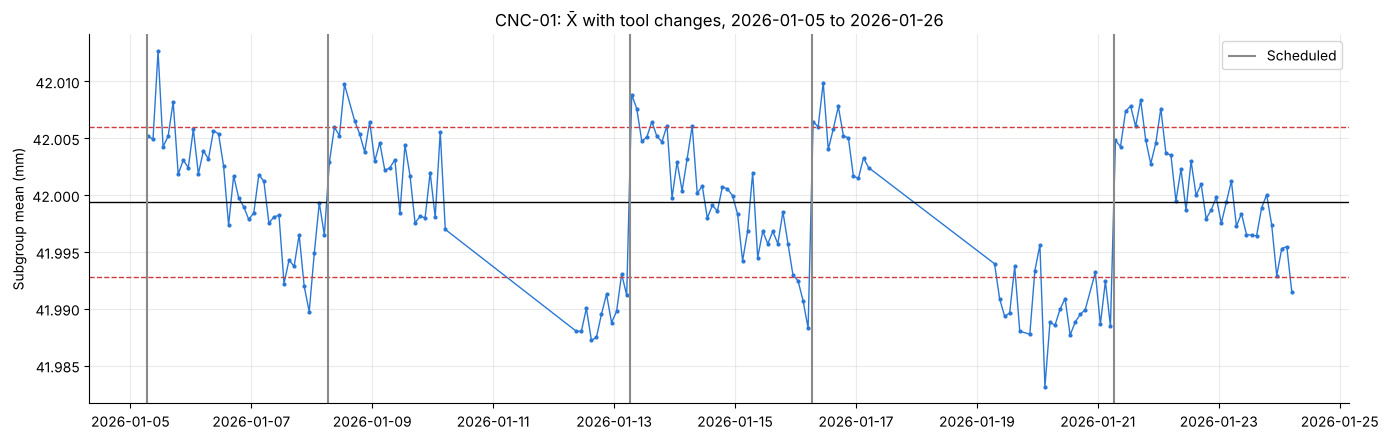

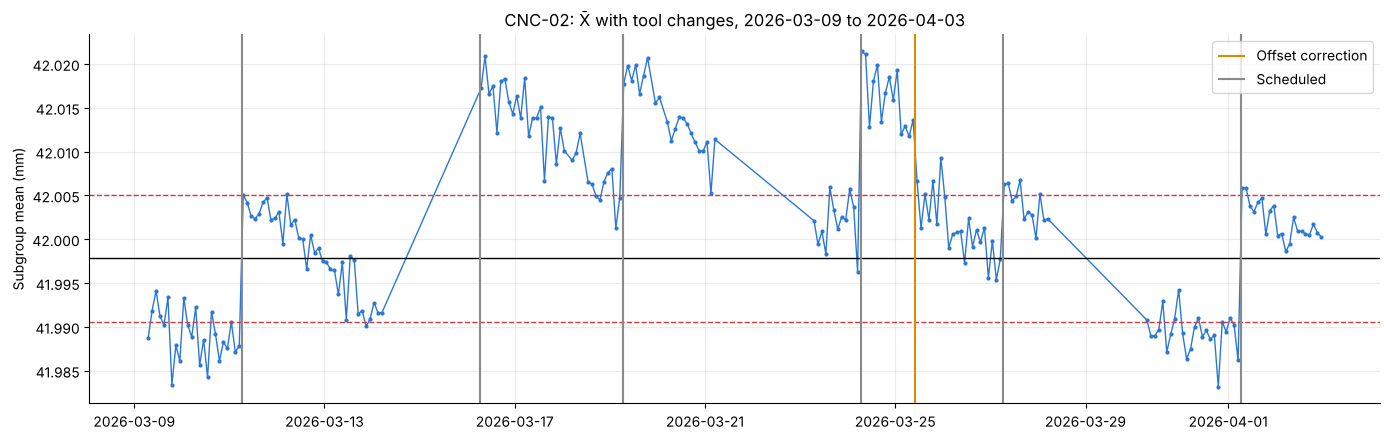

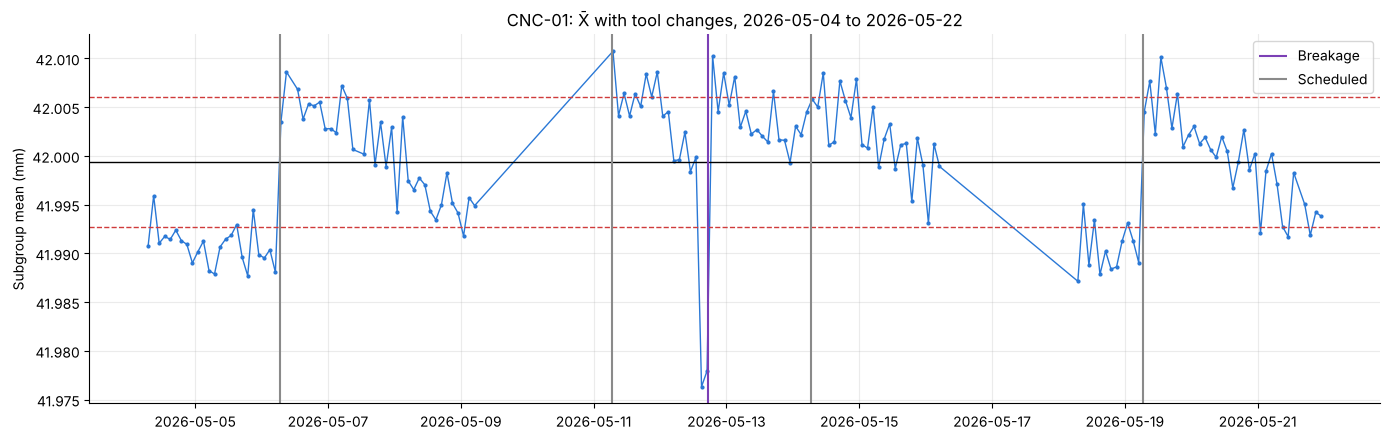

In [6]:
reason_colors = {'Scheduled': GREY, 'Offset correction': ORANGE, 'Breakage': PURPLE}

def plot_xbar_tools(machine, start, end):
    data = chart[(chart['machine_id'] == machine) &
                 (chart['measured_at'] >= start) & (chart['measured_at'] <= end)]
    lim = limits[limits['machine_id'] == machine].iloc[0]
    tools = df_tools[(df_tools['machine_id'] == machine) &
                     (df_tools['change_timestamp'] >= start) & (df_tools['change_timestamp'] <= end)]

    fig, ax = plt.subplots(figsize=(14, 4.5))
    ax.plot(data['measured_at'], data['xbar'], color=BLUE, lw=1, marker='o', ms=2)
    ax.axhline(lim['X_double_bar'], color='black', lw=1)
    for v in (lim['UCL_X'], lim['LCL_X']):
        ax.axhline(v, color=RED, ls='--', lw=1)
    ymin, ymax = ax.get_ylim()
    for reason, group in tools.groupby('reason'):
        ax.vlines(group['change_timestamp'], ymin, ymax, color=reason_colors[reason], lw=1.5, label=reason)
    ax.set_ylim(ymin, ymax)
    ax.set_ylabel('Subgroup mean (mm)')
    ax.set_title(f'{machine}: X̄ with tool changes, {start} to {end}')
    ax.legend(loc='upper right')
    plt.tight_layout()
    plt.show()

plot_xbar_tools('CNC-01', '2026-01-05', '2026-01-26')   # normal tool wear
plot_xbar_tools('CNC-02', '2026-03-09', '2026-04-03')   # the March shift
plot_xbar_tools('CNC-01', '2026-05-04', '2026-05-22')   # the May drop

In [7]:
# Tool changes that were not scheduled
df_tools[df_tools['reason'] != 'Scheduled']

,machine_id,change_timestamp,tool_id,reason
31,CNC-01,2026-05-12 17:30:00,01-T032,Breakage
63,CNC-02,2026-03-25 10:00:00,02-T021,Offset correction


In [8]:
# The CNC-01 breakage, subgroup by subgroup
chart.loc[(chart['machine_id'] == 'CNC-01') &
          chart['measured_at'].between('2026-05-12 11:00', '2026-05-12 21:00'),
          ['measured_at', 'shift', 'xbar', 'R', 'x_out', 'r_out']].round(4)

,measured_at,shift,xbar,R,x_out,r_out
1075,2026-05-12 11:00:00,A,41.9984,0.0100,False,False
1076,2026-05-12 13:00:00,A,41.9999,0.0052,False,False
1077,2026-05-12 15:00:00,B,41.9763,0.0270,True,True
1078,2026-05-12 17:00:00,B,41.9779,0.0117,True,False
1079,2026-05-12 19:00:00,B,42.0103,0.0078,True,False
1080,2026-05-12 21:00:00,B,42.0045,0.0082,False,False


**Findings**

- **Tool wear (all machines).** Every jump up happens exactly at a scheduled tool change. A new tool makes the largest bore (about 42.005 mm), and as it wears the bore shrinks steadily, to about 41.990 mm before the next change. The parts stay in specification, but this drift uses a large part of the tolerance and is the main reason so many points fall outside the control limits.
- **CNC-02 offset error (16–25 March).** At the tool changes on 16, 19 and 24 March, each new tool started about 0.013 mm higher than normal, while the wear rate stayed normal. The **setup** was wrong, not the tool, most likely a wrong tool offset. The *Offset correction* on 25 March, made in the middle of a tool's life, dropped the level straight back to normal. This matches the oversize defects found in SQL on those days.
- **CNC-01 tool breakage (12 May, shift B).** The 15:00 subgroup fell to 41.976 mm, close to the LSL, and both charts signalled at the same moment. The tool was only replaced at 17:30, so about **2.5 hours of production** ran after the first signal.

**Actions:** a first-part check after every tool change, and a rule to stop and inspect at the first out-of-control signal.

## 4. Process capability (Cp, Cpk, Pp, Ppk)

Capability compares the **width of the specification** with the **width of the process** (6σ). The four indices differ in which σ they use and whether they check centring:

| | σ used | Answers |
|---|---|---|
| **Cp, Cpk** | σ within = R̄ / d2 (5 parts made together) | What the process **could** do if it never drifted |
| **Pp, Ppk** | σ overall (all parts, whole period) | What the customer **actually received** |

Cp and Pp compare widths only. Cpk and Ppk also check how close the mean is to the **nearest** limit.

In [9]:
cap = (df_measurements.groupby('machine_id')
       .agg(mean=('bore_diameter_clean', 'mean'), sigma_overall=('bore_diameter_clean', 'std'))
       .reset_index()
       .merge(subgroups.groupby('machine_id').agg(R_bar=('R', 'mean')).reset_index(), on='machine_id'))

cap['sigma_within'] = cap['R_bar'] / d2
cap['Cp']  = (USL - LSL) / (6 * cap['sigma_within'])
cap['Cpk'] = np.minimum(USL - cap['mean'], cap['mean'] - LSL) / (3 * cap['sigma_within'])
cap['Pp']  = (USL - LSL) / (6 * cap['sigma_overall'])
cap['Ppk'] = np.minimum(USL - cap['mean'], cap['mean'] - LSL) / (3 * cap['sigma_overall'])
cap['loss_Cpk_to_Ppk_%'] = (1 - cap['Ppk'] / cap['Cpk']) * 100

cap.round(4)

,machine_id,mean,sigma_overall,R_bar,sigma_within,Cp,Cpk,Pp,Ppk,loss_Cpk_to_Ppk_%
0,CNC-01,41.9991,0.0073,0.0119,0.0051,1.6255,1.5697,1.1385,1.0994,29.9613
1,CNC-02,41.9982,0.0083,0.0122,0.0053,1.5840,1.4708,1.0062,0.9343,36.4792
2,CNC-03,41.9981,0.0080,0.0135,0.0058,1.4367,1.3268,1.0371,0.9578,27.8115


**Findings**

- **No machine meets Ppk ≥ 1.33** (1.10, 0.93 and 0.96). Cpk passes on CNC-01 and CNC-02. CNC-03 is at 1.3268, just below, and must not be rounded up to 1.33.
- **The machines are capable and well centred.** Cp is 1.44–1.63, and Cpk is only 3–8% below Cp, so centring is not the problem.
- **28–36% of the capability is lost over time** (Cpk → Ppk), through tool wear, plus the offset error on CNC-02 (largest gap) and the breakage on CNC-01.
- Cpk is only valid for a process in statistical control, which this one is not (section 2). **Ppk is the honest figure for the customer.**

## 5. Capability histograms

All three histograms share the same bins and axis, so they can be compared directly.

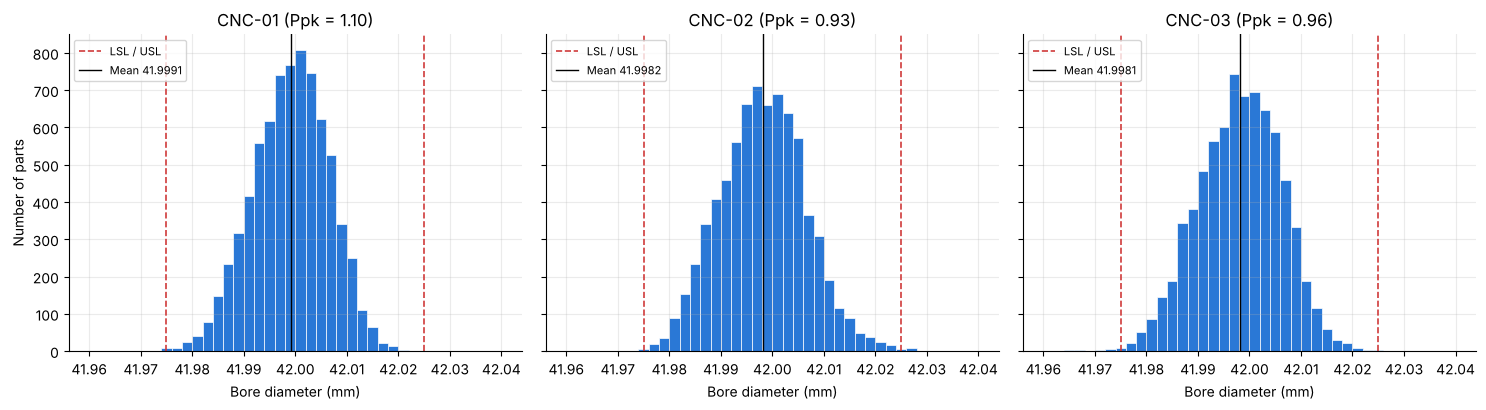

In [10]:
bins = np.arange(41.960, 42.041, 0.002)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharex=True, sharey=True)

for ax, machine in zip(axes, ['CNC-01', 'CNC-02', 'CNC-03']):
    data = df_measurements.loc[(df_measurements['machine_id'] == machine) &
                               df_measurements['bore_diameter_clean'].notna(), 'bore_diameter_clean']
    ppk = cap.loc[cap['machine_id'] == machine, 'Ppk'].iloc[0]
    ax.hist(data, bins=bins, color=BLUE, edgecolor='white', linewidth=0.5)
    ax.axvline(LSL, color=RED, ls='--', lw=1.2, label='LSL / USL')
    ax.axvline(USL, color=RED, ls='--', lw=1.2)
    ax.axvline(data.mean(), color='black', lw=1, label=f'Mean {data.mean():.4f}')
    ax.set_title(f'{machine} (Ppk = {ppk:.2f})')
    ax.set_xlabel('Bore diameter (mm)')
    ax.legend(loc='upper left', fontsize=8)
axes[0].set_ylabel('Number of parts')
plt.tight_layout()
plt.show()

In [11]:
out = df_measurements[df_measurements['bore_diameter_clean'].notna()].copy()
out['below_LSL'] = out['bore_diameter_clean'] < LSL
out['above_USL'] = out['bore_diameter_clean'] > USL
print(out.groupby('machine_id')[['below_LSL', 'above_USL']].sum())

# When did the out-of-spec parts happen? (count per machine and month)
bad = out[out['below_LSL'] | out['above_USL']]
pd.crosstab(bad['machine_id'], bad['measured_at'].dt.month.rename('month'))

            below_LSL  above_USL
machine_id                      
CNC-01              5          0
CNC-02              4         12
CNC-03             24          0


month,1,2,3,4,5,6
machine_id,,,,,,
CNC-01,1,0,0,0,4,0
CNC-02,1,0,11,0,3,1
CNC-03,0,1,1,10,7,5


**Findings**

- All three distributions are well centred, but their **tails reach the specification limits**, as expected for Ppk ≈ 1. Ppk ≥ 1.33 would need a clear gap of about 1σ between the tails and the limits.
- Each machine's out-of-spec parts come mainly from **one identifiable event**:
  - **CNC-01**: the tool breakage in May.
  - **CNC-02**: the offset error in March (11 of its 12 parts above the USL).
  - **CNC-03**: a wider spread from April (22 of its 24 parts).

## 6. Stratifying the variation by shift and operator

Tool wear moves the **centre** (X̄) but not the spread inside a subgroup (R). So R is the right measure for comparing how **consistently** different shifts and people run the process.

In [12]:
# Average subgroup range by machine and shift
subgroups.pivot_table(index='machine_id', columns='shift', values='R', aggfunc='mean').round(4)

shift,A,B,C
machine_id,,,
CNC-01,0.0118,0.0120,0.0120
CNC-02,0.0123,0.0121,0.0123
CNC-03,0.0122,0.0126,0.0158


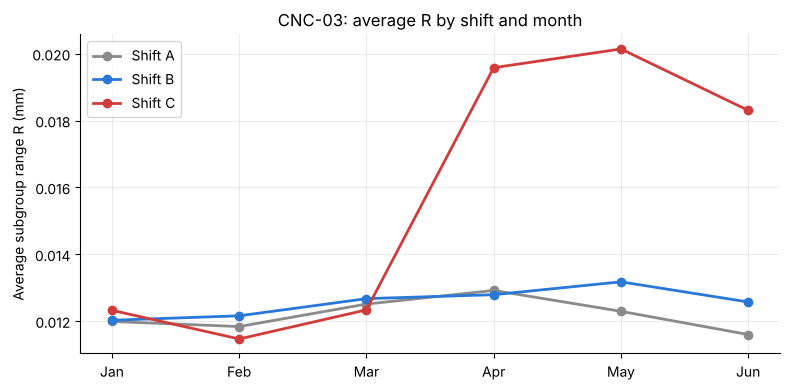

In [13]:
cnc3 = subgroups[subgroups['machine_id'] == 'CNC-03'].copy()
cnc3['month'] = cnc3['measured_at'].dt.month
r_by_month = cnc3.pivot_table(index='month', columns='shift', values='R', aggfunc='mean')

fig, ax = plt.subplots(figsize=(8, 4))
for shift, color in zip(['A', 'B', 'C'], [GREY, BLUE, RED]):
    ax.plot(r_by_month.index, r_by_month[shift], marker='o', color=color, lw=2, label=f'Shift {shift}')
ax.set_xticks(range(1, 7), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun'])
ax.set_ylabel('Average subgroup range R (mm)')
ax.set_title('CNC-03: average R by shift and month')
ax.legend()
plt.tight_layout()
plt.show()

In [14]:
# Who ran CNC-03's night shift? (number of subgroups per month and operator)
night = cnc3[cnc3['shift'] == 'C']
print(pd.crosstab(night['month'], night['operator_id']), '\n')

(night.groupby('operator_id')['R'].agg(['mean', 'count'])
      .merge(df_operators, left_index=True, right_on='operator_id')
      .round(4))

operator_id  OP-07  OP-11
month                    
1               78      0
2               75      0
3               84      0
4                3     85
5                0     78
6                0     78 



,mean,count,operator_id,experience_years,home_shift
6,0.0120,240,OP-07,7.0,C
10,0.0195,241,OP-11,0.5,C


**Levene's test** checks whether two groups have the same **spread**. Individual parts include tool wear, so each part is first measured against **its own subgroup's average** (its deviation). That removes the wear and leaves only part-to-part consistency.

In [15]:
parts_c3 = df_measurements[(df_measurements['machine_id'] == 'CNC-03') &
                           (df_measurements['shift'] == 'C') &
                           df_measurements['bore_diameter_clean'].notna()].copy()
parts_c3['deviation'] = (parts_c3['bore_diameter_clean']
                         - parts_c3.groupby('subgroup_id')['bore_diameter_clean'].transform('mean'))

op07 = parts_c3.loc[parts_c3['operator_id'] == 'OP-07', 'deviation']
op11 = parts_c3.loc[parts_c3['operator_id'] == 'OP-11', 'deviation']
result = stats.levene(op07, op11)

print(f'Std of deviations: OP-07 = {op07.std():.5f}, OP-11 = {op11.std():.5f} (ratio {op11.std() / op07.std():.2f})')
print(f'Levene p-value = {result.pvalue:.2g}')

Std of deviations: OP-07 = 0.00459, OP-11 = 0.00749 (ratio 1.63)
Levene p-value = 1.6e-44


**Findings**

- Within-subgroup spread is the same on every shift for CNC-01 and CNC-02 (R ≈ 0.012 mm). On CNC-03, the **night shift's R rose from about 0.012 to 0.019–0.020 mm from April**, while shifts A and B did not change.
- On 1 April the night shift operator changed from OP-07 (7 years' experience) to OP-11 (6 months).
- Levene's test confirms the difference: the spread is **1.6× wider** (p ≈ 10⁻⁴⁴). This explains CNC-03's wider R chart, its lowest Cp, and 20 of its 24 out-of-spec parts.
- The data shows *when* the change happened, not *why*. A newly trained operator working alone on a night shift points to a gap in **onboarding and standard work**, not individual fault.

**Actions:**
- Compare how experienced and new operators run the critical steps.
- Update the work instruction for those steps.
- Require skill-matrix qualification before anyone runs a machine alone.
- Verify the result on the R chart.

## 7. Surface roughness: one-sided capability and material lots

Roughness has only an upper limit (smoother is always fine), so capability uses only the upper side:

```
PPU = (USL − mean) / 3σ_overall        CPU = (USL − mean) / 3σ_within
```

In [16]:
ra = df_measurements['surface_roughness_ra_um']

r_sub = (df_measurements.groupby(['machine_id', 'subgroup_id'])['surface_roughness_ra_um']
         .agg(R=lambda s: s.max() - s.min(), n='count').reset_index())
sigma_within_ra = r_sub.loc[r_sub['n'] == 5, 'R'].mean() / d2

print(f'CPU (within σ)  = {(USL_RA - ra.mean()) / (3 * sigma_within_ra):.2f}')
print(f'PPU (overall σ) = {(USL_RA - ra.mean()) / (3 * ra.std()):.2f}\n')

ra_machine = (df_measurements.groupby('machine_id')
              .agg(mean_ra=('surface_roughness_ra_um', 'mean'), std_ra=('surface_roughness_ra_um', 'std'))
              .reset_index())
ra_machine['PPU'] = (USL_RA - ra_machine['mean_ra']) / (3 * ra_machine['std_ra'])
ra_machine.round(3)

CPU (within σ)  = 1.71
PPU (overall σ) = 1.14



,machine_id,mean_ra,std_ra,PPU
0,CNC-01,0.981,0.187,1.102
1,CNC-02,0.981,0.179,1.152
2,CNC-03,0.980,0.177,1.166


In [17]:
by_lot = (df_measurements.groupby('material_lot')
          .agg(mean_ra=('surface_roughness_ra_um', 'mean'),
               std_ra=('surface_roughness_ra_um', 'std'),
               n_parts=('surface_roughness_ra_um', 'count'),
               n_over=('surface_roughness_ra_um', lambda s: (s > USL_RA).sum()))
          .reset_index()
          .merge(df_lots, left_on='material_lot', right_on='lot_id'))
by_lot['PPU'] = (USL_RA - by_lot['mean_ra']) / (3 * by_lot['std_ra'])

# The five worst lots
by_lot.sort_values('PPU')[['material_lot', 'supplier_id', 'hardness_hb', 'mean_ra', 'n_over', 'PPU']].head(5).round(3)

,material_lot,supplier_id,hardness_hb,mean_ra,n_over,PPU
20,L-2026-041,SUP-02,242.0,1.436,137,0.348
18,L-2026-039,SUP-03,206.5,0.964,3,1.249
9,L-2026-030,SUP-02,206.1,0.967,0,1.291
10,L-2026-031,SUP-01,209.9,0.976,0,1.304
3,L-2026-024,SUP-01,212.6,0.976,0,1.311


All 25 lots:     r = 0.95, p = 6.6e-13
Without lot 041: r = 0.49, p = 0.015
PPU without lot 041 = 1.37


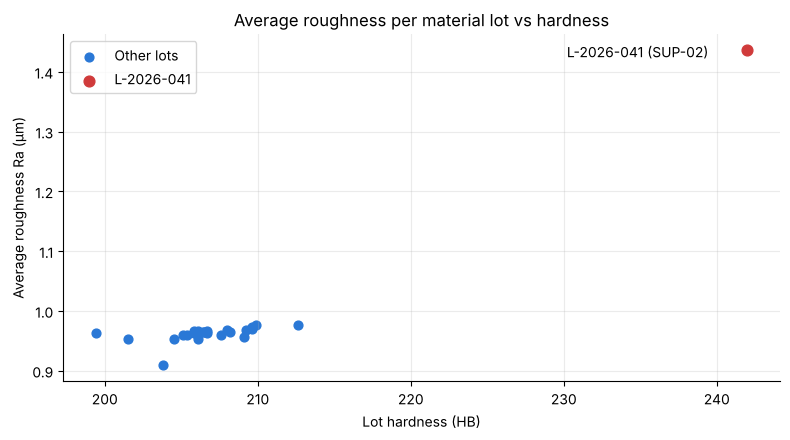

In [18]:
bad_lot = by_lot['material_lot'] == 'L-2026-041'

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(by_lot.loc[~bad_lot, 'hardness_hb'], by_lot.loc[~bad_lot, 'mean_ra'], color=BLUE, s=40, label='Other lots')
ax.scatter(by_lot.loc[bad_lot, 'hardness_hb'], by_lot.loc[bad_lot, 'mean_ra'], color=RED, s=60, label='L-2026-041')
ax.annotate('L-2026-041 (SUP-02)', (by_lot.loc[bad_lot, 'hardness_hb'].iloc[0], by_lot.loc[bad_lot, 'mean_ra'].iloc[0]),
            xytext=(-130, -5), textcoords='offset points')
ax.set_xlabel('Lot hardness (HB)')
ax.set_ylabel('Average roughness Ra (µm)')
ax.set_title('Average roughness per material lot vs hardness')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

r_all = stats.pearsonr(by_lot['hardness_hb'], by_lot['mean_ra'])
r_normal = stats.pearsonr(by_lot.loc[~bad_lot, 'hardness_hb'], by_lot.loc[~bad_lot, 'mean_ra'])
print(f'All 25 lots:     r = {r_all.statistic:.2f}, p = {r_all.pvalue:.2g}')
print(f'Without lot 041: r = {r_normal.statistic:.2f}, p = {r_normal.pvalue:.2g}')

ra_ok = df_measurements.loc[df_measurements['material_lot'] != 'L-2026-041', 'surface_roughness_ra_um']
print(f'PPU without lot 041 = {(USL_RA - ra_ok.mean()) / (3 * ra_ok.std()):.2f}')

**Findings**

- Roughness PPU is **1.14** overall and similar on all machines (1.10–1.17), so the cause is not machine-related.
- **One material lot**, L-2026-041 (supplier SUP-02, **242 HB**, against 199–213 HB for every other lot, used 25–29 May), had an average Ra of 1.44 µm. It produced **137 of the 140** out-of-spec parts, 15% of the lot.
- **Without this lot, PPU = 1.37** and roughness meets the requirement.
- The strong correlation across lots (r = 0.95) comes from that **single lot**. Within the normal hardness range the relationship is weak (r = 0.49) and its effect on Ra is negligible. There is no data between 213 and 242 HB, so the exact hardness limit cannot be set from this data.

**Actions:**
- A hardness check at incoming inspection, with a reject limit agreed with engineering.
- A supplier corrective action request to SUP-02 (the same supplier also has chronic porosity in the SQL analysis).
- A containment check for any shipped parts from lot 041.

## 8. Verifying an improvement (CNC-01, June)

CNC-01 looked calmer in June. To verify an improvement properly:

1. Find **when** it changed.
2. Compare before with after, using the **other machines as a control group** (did everyone improve, or only CNC-01?).
3. **Test** whether the difference is real.
4. Identify **what kind** of improvement it is.

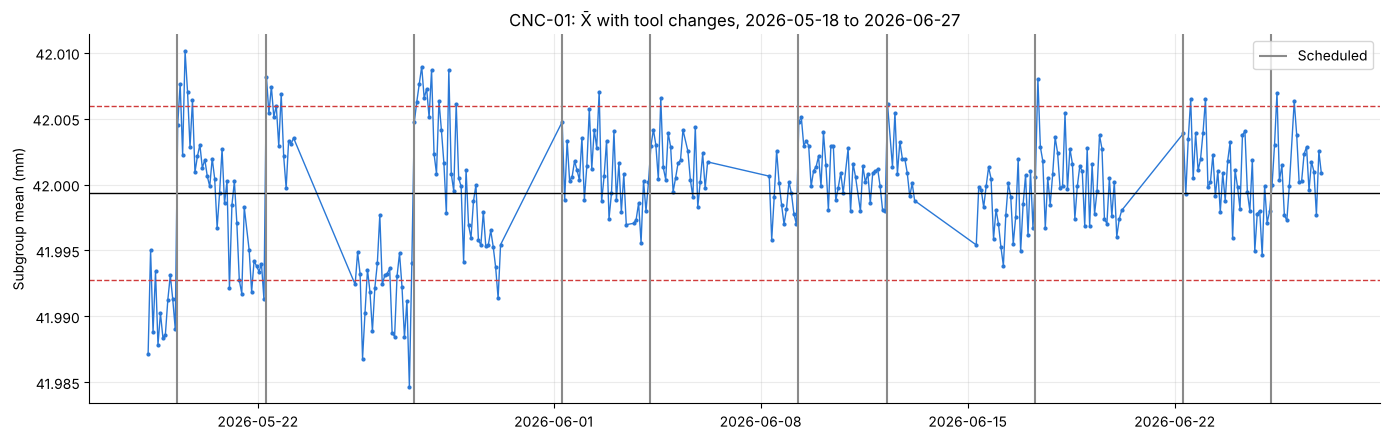

In [19]:
plot_xbar_tools('CNC-01', '2026-05-18', '2026-06-27')

In [20]:
df_cap = df_measurements[df_measurements['bore_diameter_clean'].notna()].copy()
df_cap['period'] = np.where(df_cap['measured_at'] >= '2026-06-01', 'After', 'Before')

def ppk(s):
    return min(USL - s.mean(), s.mean() - LSL) / (3 * s.std())

def pp(s):
    return (USL - LSL) / (6 * s.std())

(df_cap.groupby(['machine_id', 'period'])
       .agg(mean=('bore_diameter_clean', 'mean'),
            sigma_overall=('bore_diameter_clean', 'std'),
            n_parts=('bore_diameter_clean', 'count'),
            Ppk=('bore_diameter_clean', ppk))
       .round(4))

mean  sigma_overall  n_parts     Ppk
machine_id period                                         
CNC-01     After   42.0005         0.0053     1193  1.5456
           Before  41.9989         0.0076     6280  1.0451
CNC-02     After   41.9965         0.0077     1190  0.9283
           Before  41.9985         0.0083     6265  0.9400
CNC-03     After   41.9980         0.0086     1197  0.8972
           Before  41.9981         0.0079     6271  0.9707

In [21]:
c1 = df_cap[df_cap['machine_id'] == 'CNC-01']
before = c1.loc[c1['period'] == 'Before', 'bore_diameter_clean']
after  = c1.loc[c1['period'] == 'After',  'bore_diameter_clean']
print(f'Std before = {before.std():.4f}, after = {after.std():.4f} ({(1 - after.std() / before.std()) * 100:.0f}% lower)')
print(f'Levene p-value = {stats.levene(before, after).pvalue:.2g}\n')

# What kind of improvement? Within-subgroup spread before and after
subgroups['period'] = np.where(subgroups['measured_at'] >= '2026-06-01', 'After', 'Before')
subgroups.pivot_table(index='machine_id', columns='period', values='R', aggfunc='mean').round(4)

Std before = 0.0076, after = 0.0053 (31% lower)
Levene p-value = 4.2e-48



period,After,Before
machine_id,,
CNC-01,0.0118,0.0119
CNC-02,0.0120,0.0123
CNC-03,0.0141,0.0134


**Findings**

- From 1 June, the sawtooth on CNC-01 almost disappears. Tools are still changed on the same schedule, but the drift within each tool's life falls from about 0.013–0.017 mm to about 0.003–0.009 mm.
- **Ppk rose from 1.05 to 1.55**, meeting the 1.33 requirement. The overall standard deviation fell by 31% (Levene p ≈ 10⁻⁴⁸).
- The **control group did not improve** (CNC-02 0.94 → 0.93, CNC-03 0.97 → 0.90), so the effect is specific to CNC-01.
- R did not change, so part-to-part spread is unchanged and only the **drift over time** was removed. That is the fingerprint of **tool-wear compensation**.
- The change is **not recorded** in the tool change log.

**Actions:**
- Document the change under change management.
- Roll it out to CNC-02 and CNC-03 with the same verification.
- Recalculate CNC-01's control limits from the new process.
- Keep monitoring: the "after" period is only one month.

## 9. Tool life: how fast does the bore drift?

For every part, the tool's age is the time since its tool change. A straight line fitted through *diameter vs hours* gives the wear rate. Only **normal data** is used: the CNC-01 period after June, the CNC-02 offset error and the broken tool are excluded, and only the first 72 hours of each tool are kept (tools that run over a weekend sit idle for two days).

In [22]:
parts = df_measurements[df_measurements['bore_diameter_clean'].notna()].merge(
            df_tools[['tool_id', 'change_timestamp']], on='tool_id', how='left')
parts['hours_on_tool'] = (parts['measured_at'] - parts['change_timestamp']).dt.total_seconds() / 3600

abnormal = (((parts['machine_id'] == 'CNC-01') & (parts['measured_at'] >= '2026-06-01'))
            | ((parts['machine_id'] == 'CNC-02') & (parts['measured_at'] >= '2026-03-16')
                                                 & (parts['measured_at'] < '2026-03-25 10:00'))
            | (parts['tool_id'] == '01-T031'))            # the tool that broke on 12 May
normal = parts[~abnormal & (parts['hours_on_tool'] <= 72)].copy()

wear = stats.linregress(normal['hours_on_tool'], normal['bore_diameter_clean'])
print(f'Start size (new tool) = {wear.intercept:.4f} mm')
print(f'Wear rate             = {wear.slope:.6f} mm per hour  ({wear.slope * 24:.4f} mm per day)')
print(f'Drift over 72 hours   = {wear.slope * 72:.4f} mm')
print(f'r = {wear.rvalue:.2f}  (r² = {wear.rvalue ** 2:.2f})')
print(f'Average passes nominal 42.000 after {(wear.intercept - NOMINAL) / -wear.slope:.0f} hours')

Start size (new tool) = 42.0062 mm
Wear rate             = -0.000193 mm per hour  (-0.0046 mm per day)
Drift over 72 hours   = -0.0139 mm
r = -0.58  (r² = 0.34)
Average passes nominal 42.000 after 32 hours


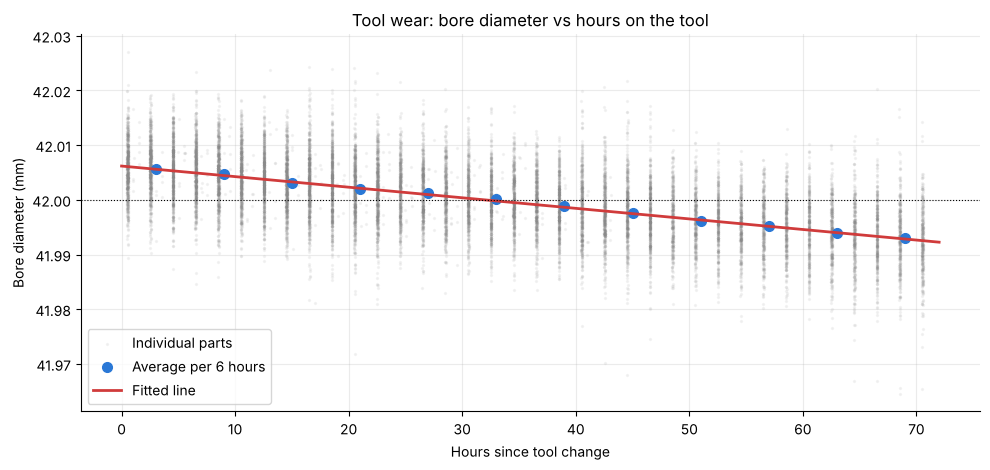

In [23]:
normal['hour_bin'] = pd.cut(normal['hours_on_tool'], bins=range(0, 73, 6))
avg = normal.groupby('hour_bin', observed=True)['bore_diameter_clean'].mean()

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.scatter(normal['hours_on_tool'], normal['bore_diameter_clean'], s=2, alpha=0.08, color=GREY, label='Individual parts')
ax.plot([b.mid for b in avg.index], avg.values, 'o', color=BLUE, ms=7, label='Average per 6 hours')
x = np.array([0, 72])
ax.plot(x, wear.intercept + wear.slope * x, color=RED, lw=2, label='Fitted line')
ax.axhline(NOMINAL, color='black', lw=0.8, ls=':')
ax.set_xlabel('Hours since tool change')
ax.set_ylabel('Bore diameter (mm)')
ax.set_title('Tool wear: bore diameter vs hours on the tool')
ax.legend(loc='lower left')
plt.tight_layout()
plt.show()

**What-if: changing tools more often.** With tools changed every *H* hours, the parts would look like the parts made in the first *H* hours of each tool. **Ppk** shows the result with the current start setting. **Pp** shows the best possible result if the new-tool setting were also re-centred.

In [24]:
results = []
for H in [24, 36, 48, 60, 72]:
    keep = normal[normal['hours_on_tool'] <= H]
    row = {'change_every_hours': H, 'mean_size': round(keep['bore_diameter_clean'].mean(), 4)}
    for machine in ['CNC-01', 'CNC-02', 'CNC-03']:
        s = keep.loc[keep['machine_id'] == machine, 'bore_diameter_clean']
        row[machine + ' Ppk'] = round(ppk(s), 2)
        row[machine + ' Pp'] = round(pp(s), 2)
    results.append(row)

pd.DataFrame(results)

,change_every_hours,mean_size,CNC-01 Ppk,CNC-01 Pp,CNC-02 Ppk,CNC-02 Pp,CNC-03 Ppk,CNC-03 Pp
0,24,42.0039,1.28,1.58,1.33,1.53,1.19,1.39
1,36,42.0030,1.28,1.51,1.35,1.48,1.23,1.39
2,48,42.0019,1.28,1.44,1.34,1.41,1.21,1.31
3,60,42.0011,1.26,1.36,1.33,1.35,1.21,1.26
4,72,42.0001,1.23,1.28,1.24,1.27,1.17,1.17


**Findings**

- The bore shrinks by **0.000193 mm per hour**: 0.0046 mm per day, or **0.014 mm over a 72-hour tool life (28% of the tolerance)**.
- A new tool starts at 42.006 mm, and the average passes nominal after about 32 hours.
- Tool age explains about a third of the variation (r = −0.58). The rest is part-to-part spread, which no tool-change schedule can remove.
- **A shorter interval alone does not help** (Ppk stays about 1.2–1.35), because only the early, oversize parts are kept and the average moves towards the USL.
- Combined with **re-centring** the new-tool setting, a **48-hour** interval would give Pp 1.44 (CNC-01) and 1.41 (CNC-02). CNC-03 would reach 1.31, or 1.48 with its pre-April night-shift spread.
- **Wear compensation is the better option.** It is already proven on CNC-01 (Ppk 1.55), and it avoids the extra tool cost and the extra risk of each tool change (the CNC-02 offset error happened at tool changes).
- **Fallback** if compensation is not possible: a 48-hour interval with the new-tool offset lowered by about 0.002 mm.

## 10. Conclusions and recommendations

**Answer to the Quality Manager:** the process is **not yet capable** (Ppk 0.93–1.10 against 1.33 required). The machines are capable, though, and the causes are known and fixable.

| # | Problem | Machines | Evidence | Recommended action | Priority |
|---|---|---|---|---|---|
| 1 | Tool-wear drift (0.014 mm per tool) | All | §2, §3, §4, §9 | Roll out wear compensation (proven on CNC-01: Ppk 1.05 → 1.55) | **1** |
| 2 | Night-shift spread 1.6× wider since April | CNC-03 | §6 | Compare methods, update work instruction, skill-matrix qualification | 2 |
| 3 | Over-hard material lot (roughness) | All | §7 | Incoming hardness check, supplier corrective action, containment | 2 |
| 4 | Offset error at tool changes | CNC-02 | §3, §5 | First-part check after every tool change | 3 |
| 5 | Late reaction to a tool breakage | CNC-01 | §3 | Stop and inspect at the first SPC signal | 3 |
| 6 | Undocumented process change | CNC-01 | §8 | Change-management record; recalculate control limits | 3 |

**Limitations**

- The data is synthetic.
- The "after" period for CNC-01 is one month.
- Control limits come from a baseline that was itself not in control.
- The hardness limit for incoming material cannot be set from this data, because there are no lots between 213 and 242 HB.